# Random Forest – bộ feature sạch (bỏ `Id`), target `SalePrice` gốc (Ames Housing)

**Mục tiêu:** phiên bản riêng của mình, **không biến đổi log**, để so với RF đầu tiên của An (`baseline/baseline.ipynb`) và với bản đã có (`15-11-2026-Nguyen-random-forest-clean-log1p`, target `log1p`).

| | RF đầu tiên của An | Bản đã có (log1p) | **Bản này** |
|---|---|---|---|
| Feature | `processed/` (35 feature gốc, 146 cột) | toàn bộ feature sạch trừ `Id` | **toàn bộ feature sạch trừ `Id`** (80 feature, 288 cột sau mã hóa) |
| Target | `log1p(SalePrice)` | `log1p(SalePrice)` | **`SalePrice` gốc (USD)** |
| Tham số | mặc định | mặc định | **mặc định** |
| Chia dữ liệu | 80/20, seed 42 | giống hệt | **giống hệt** (có kiểm tra) |

Bản này khác An ở **hai thứ cùng lúc** (bộ feature và target), nên có **ma trận 2×2** (Run 2) để tách phần đóng góp của từng thứ.

## Params

In [1]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
SEEDS = [0, 1, 2, 3, 4]

# Điểm của An ghi trong baseline/baseline.ipynb (RF mặc định, tập valid 292 dòng, RMSE tính bằng USD)
AN_RF_VALID_RMSE = 27713
AN_RF_KAGGLE = 0.16285

## import thư viện

In [2]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

sns.set_theme(style="whitegrid")
Path("figures").mkdir(exist_ok=True)
Path("data").mkdir(exist_ok=True)

## Đọc dữ liệu

* **Bộ sạch:** `cleaned_data.csv` bỏ `Id`. Đọc với `keep_default_na=False` vì nhãn `None` (ví dụ `MasVnrType`) sẽ bị hiểu nhầm là thiếu.
* **Bộ của An:** `processed/X_train.csv`, `X_test.csv`.

In [3]:
CLEAN = Path("../../../data/clean")
RAW = Path("../../../data/raw")
PROC = Path("../../../data/processed")

df = pd.read_csv(CLEAN / "cleaned_data.csv", keep_default_na=False, na_values=[""])
ids = df["Id"]
df = df.drop(columns="Id")                      # Id chỉ để ghi file nộp, không đưa vào model
print(df.shape, "| NaN còn lại:", int(df.isna().sum().sum()))

X = df.drop(columns="SalePrice")
y = df["SalePrice"]
assert "Id" not in X.columns

X_train, X_valid, y_train, y_valid, id_train, id_valid = train_test_split(
    X, y, ids, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
y_train_log = np.log1p(y_train)

Xp_train, Xp_valid = pd.read_csv(PROC / "X_train.csv"), pd.read_csv(PROC / "X_test.csv")
assert "Id" not in Xp_train.columns
assert (y_train.values == pd.read_csv(PROC / "y_train.csv")["SalePrice"].values).all()
assert (y_valid.values == pd.read_csv(PROC / "y_test.csv")["SalePrice"].values).all()

print("Bộ sạch :", X_train.shape, X_valid.shape)
print("Bộ An   :", Xp_train.shape, Xp_valid.shape)
print("Hai bộ cùng một phép chia train/valid: OK")

(1458, 81) | NaN còn lại: 0
Bộ sạch : (1166, 80) (292, 80)
Bộ An   : (1166, 146) (292, 146)
Hai bộ cùng một phép chia train/valid: OK


## Mã hóa cột phân loại cho bộ sạch

Giống các thí nghiệm Decision Tree, Random Forest và XGBoost trước: Ordinal cho 9 cột chất lượng (`Po < Fa < TA < Gd < Ex`), One-Hot cho các cột phân loại còn lại (kể cả `MSSubClass`, `MoSold`), cột số giữ nguyên, không scale.

In [4]:
quality = ["Po", "Fa", "TA", "Gd", "Ex"]
ORDINAL = {
    "ExterQual": quality, "ExterCond": quality, "KitchenQual": quality, "HeatingQC": quality,
    "BsmtQual": ["No Basement"] + quality, "BsmtCond": ["No Basement"] + quality,
    "GarageQual": ["No Garage"] + quality, "GarageCond": ["No Garage"] + quality,
    "FireplaceQu": ["No Fireplace"] + quality,
}
ordinal_cols = list(ORDINAL)
nominal_cols = [c for c in X.select_dtypes(exclude="number").columns if c not in ORDINAL] + ["MSSubClass", "MoSold"]
numeric_cols = [c for c in X.columns if c not in ordinal_cols + nominal_cols]

for col, order in ORDINAL.items():
    unseen = set(X[col].unique()) - set(order)
    assert not unseen, (col, unseen)


def make_clean_rf(seed, **rf_params):
    encoder = ColumnTransformer(
        [
            ("ordinal", OrdinalEncoder(categories=[ORDINAL[c] for c in ordinal_cols],
                                       handle_unknown="use_encoded_value", unknown_value=-1), ordinal_cols),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
            ("numeric", "passthrough", numeric_cols),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")
    return Pipeline([("encoder", encoder), ("rf", RandomForestRegressor(random_state=seed, **rf_params))])


def make_an_rf(seed):
    return RandomForestRegressor(random_state=seed)      # đúng cấu hình của An, chỉ thêm seed

## Cách chấm điểm

Mọi dự đoán được quy về **USD** rồi chấm chung một cách:
* **RMSE (USD)**: chỉ số An dùng trong baseline. MAE và R² cũng tính trên USD.
* **RMSLE**: chỉ số Kaggle dùng (RMSE trên thang log). Với target gốc, dự đoán được `clip` về tối thiểu 1 USD trước khi lấy log.

In [5]:
def evaluate(y_true, pred_usd):
    pred_usd = np.clip(pred_usd, 1, None)
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, pred_usd)),
        "MAE": mean_absolute_error(y_true, pred_usd),
        "R2": r2_score(y_true, pred_usd),
        "RMSLE": np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(pred_usd))),
    }

fmt = {"RMSE": 0, "MAE": 0, "R2": 4, "RMSLE": 4}
TARGETS = {"SalePrice gốc": (lambda v: v, lambda v: v), "log1p(SalePrice)": (np.log1p, np.expm1)}

## Run 1 – RF mặc định, bộ feature sạch, target `SalePrice` gốc (seed 42)

In [6]:
run1 = make_clean_rf(RANDOM_STATE).fit(X_train, y_train)
p1_train, p1_valid = run1.predict(X_train), run1.predict(X_valid)

print("Số cột sau mã hóa:", run1.named_steps["encoder"].get_feature_names_out().size)
res1 = pd.DataFrame({"train": evaluate(y_train, p1_train), "valid": evaluate(y_valid, p1_valid)}).T
res1.round(fmt)

Số cột sau mã hóa: 288


,RMSE,MAE,R2,RMSLE
train,10549.0,6513.0,0.9829,0.0581
valid,24507.0,17201.0,0.8913,0.1476


**Nhận xét:**
- RF mặc định trên bộ sạch, target gốc (seed 42): RMSE valid **24.507 USD**, MAE 17.201 USD, R² 0,8913, RMSLE 0,1476.
- Overfit nhẹ: RMSLE train 0,0581 so với valid 0,1476. Tuy vậy điểm valid tốt hơn RF của An (27.713 USD, ghi lại) khoảng 3.200 USD.

## Run 2 – Ma trận 2×2: tách ảnh hưởng của bộ feature và của target

Cùng tham số mặc định, cùng seed 42, cùng phép chia. Ô (bộ An, `log1p`) là RF của An chạy lại để kiểm tra tái lập.

In [7]:
res = {}
for feat_name, make, A, B in [
    ("Bộ An (35 feature)", lambda s: make_an_rf(s), Xp_train, Xp_valid),
    ("Bộ sạch (80 feature)", make_clean_rf, X_train, X_valid),
]:
    for tgt_name, (fwd, inv) in TARGETS.items():
        m = make(RANDOM_STATE).fit(A, fwd(y_train))
        res[(feat_name, tgt_name)] = evaluate(y_valid, inv(m.predict(B)))

grid = pd.DataFrame(res).T
grid.index.names = ["bộ feature", "target"]
print(f"Điểm An ghi trong baseline.ipynb: RMSE valid = {AN_RF_VALID_RMSE:,}")
grid.round(fmt)

Điểm An ghi trong baseline.ipynb: RMSE valid = 27,713


RMSE      MAE      R2   RMSLE
bộ feature           target                                            
Bộ An (35 feature)   SalePrice gốc     27476.0  19068.0  0.8633  0.1628
                     log1p(SalePrice)  27083.0  18772.0  0.8672  0.1560
Bộ sạch (80 feature) SalePrice gốc     24507.0  17201.0  0.8913  0.1476
                     log1p(SalePrice)  24047.0  16511.0  0.8953  0.1426

In [8]:
pivot = {}
for metric in ["RMSE", "RMSLE"]:
    p = grid[metric].unstack("target")[["log1p(SalePrice)", "SalePrice gốc"]]
    p["đổi sang target gốc"] = p["SalePrice gốc"] - p["log1p(SalePrice)"]
    p.loc["đổi sang bộ sạch"] = p.loc["Bộ sạch (80 feature)"] - p.loc["Bộ An (35 feature)"]
    pivot[metric] = p
print("RMSE (USD)"); display(pivot["RMSE"].round(0))
print("RMSLE");      display(pivot["RMSLE"].round(4))

RMSE (USD)


target,log1p(SalePrice),SalePrice gốc,đổi sang target gốc
bộ feature,,,
Bộ An (35 feature),27083.0,27476.0,394.0
Bộ sạch (80 feature),24047.0,24507.0,460.0
đổi sang bộ sạch,-3036.0,-2970.0,66.0


RMSLE


target,log1p(SalePrice),SalePrice gốc,đổi sang target gốc
bộ feature,,,
Bộ An (35 feature),0.1560,0.1628,0.0068
Bộ sạch (80 feature),0.1426,0.1476,0.0049
đổi sang bộ sạch,-0.0133,-0.0152,-0.0019


**Nhận xét:**
- Chạy lại RF của An (ô *Bộ An + log1p*) cho RMSE valid **27.064 USD**, gần con số An ghi (27.713) và nằm trong độ dao động do RF không đặt seed (Run 3), nên **cấu hình của An tái lập được**.
- **Bộ feature sạch là nguồn cải thiện chính:** giảm RMSE khoảng 3.000 USD và RMSLE 0,013 đến 0,015 ở cả hai kiểu target.
- **Target gốc không cải thiện gì thêm:** ở seed 42 nó *kém hơn* log1p khoảng 410 đến 500 USD (RMSE) và 0,005 đến 0,007 (RMSLE) trên cả hai bộ feature. Mức chênh này nhỏ so với hiệu ứng của bộ feature, nhưng cần xem Run 3 để biết có vượt độ dao động theo seed không.

## Run 3 – Độ dao động theo seed

RF không cố định seed thì mỗi lần chạy một điểm khác (RF của An cũng không đặt seed). Chạy cả bốn ô của ma trận với 5 seed để biết chênh lệch có lớn hơn độ dao động này không.

In [9]:
rows = []
for seed in SEEDS:
    for feat_name, make, A, B in [
        ("Bộ An (35 feature)", make_an_rf, Xp_train, Xp_valid),
        ("Bộ sạch (80 feature)", make_clean_rf, X_train, X_valid),
    ]:
        for tgt_name, (fwd, inv) in TARGETS.items():
            m = make(seed).fit(A, fwd(y_train))
            r = evaluate(y_valid, inv(m.predict(B)))
            rows.append({"seed": seed, "bộ feature": feat_name, "target": tgt_name,
                         "RMSE": r["RMSE"], "RMSLE": r["RMSLE"], "R2": r["R2"]})

seeds_df = pd.DataFrame(rows)
seeds_df["cấu hình"] = seeds_df["bộ feature"].str.split(" \\(").str[0] + " + " + seeds_df["target"]
seed_summary = seeds_df.groupby(["bộ feature", "target"])[["RMSE", "RMSLE", "R2"]].agg(["mean", "std", "min", "max"])
seed_summary.round(4)

RMSE                        \
                                             mean       std         min   
bộ feature           target                                               
Bộ An (35 feature)   SalePrice gốc     27469.2026  308.2527  27103.5436   
                     log1p(SalePrice)  27337.8534  268.0057  27056.5779   
Bộ sạch (80 feature) SalePrice gốc     24211.8274  438.5863  23486.6952   
                     log1p(SalePrice)  24399.4065  198.5868  24205.1408   

                                                    RMSLE                  \
                                              max    mean     std     min   
bộ feature           target                                                 
Bộ An (35 feature)   SalePrice gốc     27862.7507  0.1626  0.0011  0.1613   
                     log1p(SalePrice)  27736.8718  0.1552  0.0016  0.1531   
Bộ sạch (80 feature) SalePrice gốc     24569.4611  0.1463  0.0009  0.1451   
                     log1p(SalePrice)  24619.6075  0.1435  0.0009  0.1424   

                                                   R2                          
                                          max    mean     std     min     max  
bộ feature           target                                                    
Bộ An (35 feature)   SalePrice gốc     0.1643  0.8634  0.0031  0.8595  0.8670  
                     log1p(SalePrice)  0.1569  0.8647  0.0027  0.8607  0.8675  
Bộ sạch (80 feature) SalePrice gốc     0.1477  0.8938  0.0038  0.8907  0.9001  
                     log1p(SalePrice)  0.1446  0.8922  0.0018  0.8903  0.8939

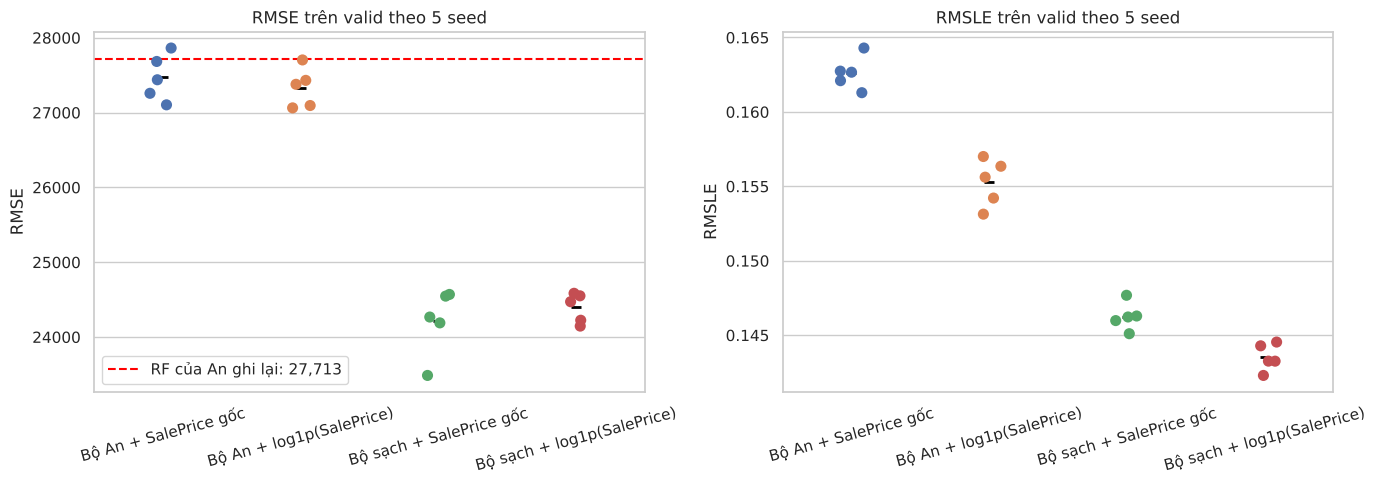

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = sorted(seeds_df["cấu hình"].unique())
for ax, metric in [(axes[0], "RMSE"), (axes[1], "RMSLE")]:
    sns.stripplot(data=seeds_df, x="cấu hình", y=metric, hue="cấu hình", order=order, s=8, ax=ax, legend=False)
    sns.pointplot(data=seeds_df, x="cấu hình", y=metric, order=order, linestyle="none", color="black", markers="_", errorbar=None, ax=ax)
    if metric == "RMSE":
        ax.axhline(AN_RF_VALID_RMSE, color="red", linestyle="--", label=f"RF của An ghi lại: {AN_RF_VALID_RMSE:,}")
        ax.legend()
    ax.set_title(f"{metric} trên valid theo 5 seed")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("figures/rf_saleprice_goc_seed_compare.png", dpi=150)
plt.show()

**Nhận xét:**
- Bộ sạch + target gốc: RMSE valid trung bình **24.212 USD** (độ lệch chuẩn 439), bộ sạch + log1p: **24.396 USD** (độ lệch chuẩn 198). Hai khoảng dao động **chồng nhau**, nên về RMSE (USD) hai kiểu target **không phân biệt được**; ở seed 42 log1p nhỉnh hơn, ở trung bình 5 seed target gốc nhỉnh hơn.
- Về RMSLE thì log1p tốt hơn một chút và khá ổn định: 0,1435 so với 0,1463 (độ lệch chuẩn khoảng 0,001), hai khoảng không chồng nhau, nhưng chênh chỉ khoảng 0,003. Điều này hợp lý vì mô hình học trên thang log thì tối ưu thẳng cho thước đo log.
- Cả hai cấu hình bộ sạch đều **tốt hơn rõ rệt** bộ An (27.469 và 27.334 USD): chênh khoảng 2.900 đến 3.300 USD, gấp nhiều lần độ lệch chuẩn theo seed.
- Lưu ý: độ dao động này chỉ phản ánh tính ngẫu nhiên của RF, chưa phản ánh việc chọn cách chia train/valid khác.

## Run 4 – Cross-validation 5-fold trên tập train

Tập valid chỉ có 292 dòng nên so sánh thêm bằng CV trên 1.166 dòng train. Cả bốn cấu hình dùng **cùng các fold**, điểm tính bằng RMSLE trên thang log để so được giữa hai kiểu target.

In [10]:
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {}
for feat_name, make, A in [
    ("Bộ An", make_an_rf, Xp_train),
    ("Bộ sạch", make_clean_rf, X_train),
]:
    for tgt_name, (fwd, inv) in TARGETS.items():
        fold_scores = []
        for tr, va in cv.split(A):
            m = make(RANDOM_STATE).fit(A.iloc[tr], fwd(y_train.iloc[tr]))
            fold_scores.append(evaluate(y_train.iloc[va], inv(m.predict(A.iloc[va])))["RMSLE"])
        cv_scores[f"{feat_name} + {tgt_name}"] = fold_scores

cv_df = pd.DataFrame(cv_scores, index=[f"fold {i + 1}" for i in range(CV_FOLDS)])
cv_df.loc["trung bình"] = cv_df.mean()
cv_df.loc["độ lệch chuẩn"] = cv_df.iloc[:CV_FOLDS].std()
cv_df.round(4)

,Bộ An + SalePrice gốc,Bộ An + log1p(SalePrice),Bộ sạch + SalePrice gốc,Bộ sạch + log1p(SalePrice)
fold 1,0.1717,0.1741,0.1515,0.1570
fold 2,0.1519,0.1538,0.1374,0.1399
fold 3,0.1412,0.1420,0.1296,0.1288
fold 4,0.1375,0.1344,0.1351,0.1303
fold 5,0.1590,0.1583,0.1521,0.1468
trung bình,0.1523,0.1525,0.1411,0.1406
độ lệch chuẩn,0.0138,0.0153,0.0102,0.0118


**Nhận xét:**
- RMSLE CV trung bình: bộ sạch + target gốc **0,1411**, bộ sạch + log1p **0,1404**, bộ An (cả hai target) **0,1523**.
- Giữa hai kiểu target trên bộ sạch **gần như hòa**: chênh 0,0007, nhỏ hơn nhiều so với độ lệch chuẩn giữa các fold (0,010 đến 0,012); target gốc thắng 2/5 fold, log1p thắng 3/5.
- Bộ sạch (target gốc) thắng bộ An (target gốc) cả **5/5 fold**, chênh từ 0,0024 đến 0,0202.
- Với bộ An, CV chạy trên `X_train.csv` đã được mã hóa sẵn bằng bộ mã hóa fit trên toàn train; với cây quyết định (không scale) ảnh hưởng này không đáng kể.

## Tổng hợp so sánh

In [11]:
s = seed_summary
g = grid
def row(feat, tgt):
    return {"RMSE valid (seed 42)": g.loc[(feat, tgt), "RMSE"], "RMSE valid, TB 5 seed": s.loc[(feat, tgt), ("RMSE", "mean")],
            "RMSLE valid (seed 42)": g.loc[(feat, tgt), "RMSLE"],
            "RMSLE CV": cv_df.loc["trung bình", f"{feat.split(' (')[0]} + {tgt}"]}

compare = pd.DataFrame({
    "RF của An (điểm ghi lại)": {"RMSE valid (seed 42)": AN_RF_VALID_RMSE, "Kaggle": AN_RF_KAGGLE},
    "Chạy lại RF của An (bộ An + log1p)": row("Bộ An (35 feature)", "log1p(SalePrice)"),
    "Bản log1p đã có (bộ sạch + log1p)": row("Bộ sạch (80 feature)", "log1p(SalePrice)"),
    "BẢN NÀY (bộ sạch + target gốc)": row("Bộ sạch (80 feature)", "SalePrice gốc"),
}).T
compare.round({"RMSE valid (seed 42)": 0, "RMSE valid, TB 5 seed": 0, "RMSLE valid (seed 42)": 4, "RMSLE CV": 4, "Kaggle": 5})

,RMSE valid (seed 42),Kaggle,"RMSE valid, TB 5 seed",RMSLE valid (seed 42),RMSLE CV
RF của An (điểm ghi lại),27713.0,0.16285,NaN,NaN,NaN
Chạy lại RF của An (bộ An + log1p),27083.0,NaN,27338.0,0.1560,0.1525
Bản log1p đã có (bộ sạch + log1p),24047.0,NaN,24399.0,0.1426,0.1406
BẢN NÀY (bộ sạch + target gốc),24507.0,NaN,24212.0,0.1476,0.1411


**Nhận xét:** so với RF đầu tiên của An (RMSE valid 27.713 USD, Kaggle 0,16285):

| Thước đo | RF của An (chạy lại) | Bản log1p đã có | **Bản này (target gốc)** |
|---|---|---|---|
| RMSE valid, seed 42 (USD) | 27.064 | 24.003 | 24.507 |
| RMSE valid, TB 5 seed (USD) | 27.334 | 24.396 | **24.212** |
| RMSLE valid, seed 42 | 0,1558 | **0,1426** | 0,1476 |
| RMSLE CV 5-fold | 0,1523 | **0,1404** | 0,1411 |

- Bản này giảm RMSE valid trung bình 5 seed khoảng **11,4%** so với RF của An (27.334 xuống 24.212 USD), vượt xa độ dao động theo seed.
- **Không nên nói target gốc tốt hơn hay kém hơn log1p**: RMSE USD thì lẫn trong nhiễu, RMSLE thì log1p nhỉnh hơn không đáng kể. Phần cải thiện thực chất đến từ **bộ feature sạch**, không phải từ kiểu target.
- **Điểm Kaggle chưa đo được** vì chưa nộp. File dự đoán ở `data/submission_rf_clean_saleprice_goc.csv`. Dự đoán của hai bản (target gốc và log1p) giống nhau rất cao (tương quan 0,994, chênh tuyệt đối trung bình khoảng 5.200 USD).
- Hạn chế: tập valid chỉ 292 dòng; tham số RF để mặc định, chưa tinh chỉnh.

## Feature quan trọng và dự đoán so với thực tế (bản này)

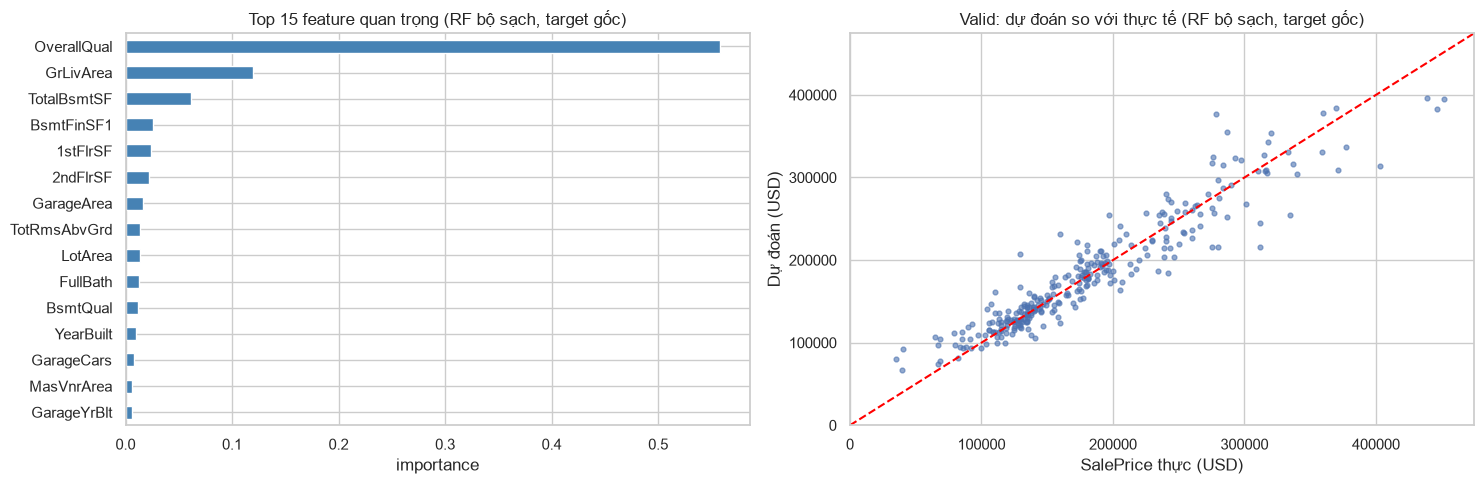

,importance
OverallQual,0.5579
GrLivArea,0.1197
TotalBsmtSF,0.0616
BsmtFinSF1,0.0262
1stFlrSF,0.0239
2ndFlrSF,0.0224
GarageArea,0.0163
TotRmsAbvGrd,0.0136
LotArea,0.0135
FullBath,0.0122


In [12]:
encoded_names = run1.named_steps["encoder"].get_feature_names_out()
importance = pd.Series(run1.named_steps["rf"].feature_importances_, index=encoded_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
importance.head(15)[::-1].plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Top 15 feature quan trọng (RF bộ sạch, target gốc)")
axes[0].set_xlabel("importance")

axes[1].scatter(y_valid, p1_valid, s=12, alpha=0.6)
lim = [0, max(y_valid.max(), p1_valid.max()) * 1.05]
axes[1].plot(lim, lim, color="red", linestyle="--")
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("SalePrice thực (USD)"); axes[1].set_ylabel("Dự đoán (USD)")
axes[1].set_title("Valid: dự đoán so với thực tế (RF bộ sạch, target gốc)")
plt.tight_layout()
plt.savefig("figures/rf_saleprice_goc_importance_pred.png", dpi=150)
plt.show()

importance.head(10).round(4).to_frame("importance")

**Nhận xét:**
- `OverallQual` chiếm **55,8%** độ quan trọng, theo sau là `GrLivArea` (12,0%), `TotalBsmtSF` (6,2%), `BsmtFinSF1` (2,6%) và `1stFlrSF` (2,4%). Thứ tự gần như giống bản log1p đã có, nên kiểu target ít ảnh hưởng đến việc RF coi feature nào quan trọng.
- Bộ feature của An không có `OverallQual`; theo thí nghiệm ablation `OverallQual` đã có, thêm riêng feature này thu hồi khoảng 40 đến 60% khoảng cách với bộ sạch, tức là một phần đáng kể nhưng không phải nguồn duy nhất.
- Biểu đồ dự đoán bám sát đường chéo ở khoảng giá thấp và trung bình. Với nhà đắt, mô hình dự đoán thấp hơn thực tế: dự đoán cao nhất trên valid khoảng 396.000 USD trong khi giá thực cao nhất 451.950 USD; 9 căn trên 350.000 USD bị dự đoán thấp trung bình khoảng 39.000 USD. Đây là đặc điểm của RF (dự đoán là trung bình các giá trong lá, không vượt khỏi khoảng giá đã thấy khi học).

# Lưu kết quả

Lưu tham số, model, dự đoán valid, bảng so sánh và file dự đoán cho Kaggle (**chưa nộp nên chưa có điểm Kaggle**).

In [13]:
params = run1.named_steps["rf"].get_params()
with open("rf_saleprice_goc_params.json", "w", encoding="utf-8") as f:
    json.dump(params, f, indent=4, ensure_ascii=False)

joblib.dump(run1, "rf_saleprice_goc_model.pkl", compress=3)

pd.DataFrame({
    "Id": id_valid.values, "SalePrice": y_valid.values,
    "pred_rf_clean_goc": p1_valid, "abs_error_rf_clean_goc": np.abs(y_valid.values - p1_valid),
}).to_csv("data/valid_predictions.csv", index=False)

compare.round(5).to_csv("rf_saleprice_goc_compare.csv", encoding="utf-8-sig")
grid.round(5).to_csv("rf_saleprice_goc_matrix_2x2.csv", encoding="utf-8-sig")

test = pd.read_csv(CLEAN / "cleaned_test.csv", keep_default_na=False, na_values=[""])
test_ids = test["Id"]
X_test = test.drop(columns="Id")[X.columns]
sample = pd.read_csv(RAW / "sample_submission.csv")
assert (test_ids.values == sample["Id"].values).all()
assert X_test.isna().sum().sum() == 0
unknown_ordinal = {c: sorted(set(X_test[c]) - set(ORDINAL[c])) for c in ordinal_cols if set(X_test[c]) - set(ORDINAL[c])}
print("Giá trị ordinal lạ trong test (bị mã hóa -1):", unknown_ordinal or "không có")

sub = pd.DataFrame({"Id": test_ids, "SalePrice": run1.predict(X_test)})
assert sub["SalePrice"].notna().all() and (sub["SalePrice"] > 0).all()
sub.to_csv("data/submission_rf_clean_saleprice_goc.csv", index=False)
print("Submission:", sub.shape, "| min", round(sub.SalePrice.min()), "| max", round(sub.SalePrice.max()))

Giá trị ordinal lạ trong test (bị mã hóa -1): không có
Submission: (1459, 2) | min 63301 | max 594401
